# Ingeniería Económica
## Tarea 3 Evaluación de proyectos con Python

> **Cuaderno práctico · Python y Jupyter Notebook · Isidora García · rol: 202573029-4**
> ###### Se utilizo 365copilot especificamente para la generacion de codigo de graficos y aproximaciones de calculo en algunos casos

> ##### Video: https://usmcl-my.sharepoint.com/:f:/g/personal/igarciap_usm_cl/IgD0tWvcOYepTJEEvV-oy2VfARDfMadJ0IHAMpdRZab-Ouo?e=Qh1fVu
> ##### Repositorio: https://github.com/Paz2712/Tarea3_Ingeco_python 

In [ ]:
"""
Esta tarea fue en su totalidad realizada en VsCode, utilizando la extension de python, jupyter y vemv para
que corra el codigo.

> en el caso que lo quieran hacer correr en VSCODE, deje un repositorio de github el cual tiene
el codigo original de la tarea, el vemv que se debe guardar para pasarlo al kerner de jupyter en vscode y
asi que corra el codigo utilizando la extension de jupyter

> en el caso de utilizar google colab;
Debido a que se creo un Virtual Enviroment local para que corriera en vscode va a tirar un error al iniciar el google colab ya que buscara el
El Virtual Enviroment local por lo que puedes correr el archivo hasta que el archivo automaticamente cambie el kerner o

1) Abres el archivo y Te metes a edit en google colab
2) entras en Notebook settings
3) buscas Runtime type
4) cambias ingeco --> python 3

Ahora para que no haya problemas con el numpy_financial
solo debe quitar el hashtag[#] para que corra el siguiente comando(↓)
si no elimina el # no va a correr la tarea en Google Colab
"""
#!pip install numpy_financial

### Parametrización mediante el Rol USM y Librerias a utilizar


In [ ]:
import numpy as np                  #aqui se encuentran todas las librerias a utilizar en esta tarea
import numpy_financial as npf
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

k= 29
semilla= 2025730294
f= 1 + k/1000
r= (0.15*k + 4)/100
print(k, "(K) ", f, "(Factor de inversión) ", round(r,2),
      "(Tasa de descuento) ", semilla, "(rol/semilla)\n")
# utilizando mi rol obtenemos el factor de inversión, tasa de descuento y la semilla

---
# <b> Parte 1, Indicadores financieros
</b>

### **Calculo y evalución de proyectos Caso: Reutiliza**

*para poder evaluar el proyecto que mas va le conviene a la empresa sacamos el flujo de caja de cada año, obteniendo asi los flujos del Proyecto A, B y C*

In [57]:
FlujoA= [-18522000.0,5000000,6500000,7500000,11000000]
FlujoB= [-37044000.0,7000000,10000000,14000000,22000000]
FlujoC= [-10290000.0,4500000,3000000,5500000,4000000]

VanA= npf.npv(r,FlujoA)
TirA= npf.irr(FlujoA)

VanB= npf.npv(r,FlujoB)
TirB= npf.irr(FlujoB)

VanC= npf.npv(r,FlujoC)
TirC= npf.irr(FlujoC)

print("Resumen: (↓)\n")

TablaFlujos = pd.DataFrame({
    "Proyecto": ["A", "B", "C"],
    "Año 0": [FlujoA[0], FlujoB[0], FlujoC[0]],
    "Año 1": [FlujoA[1], FlujoB[1], FlujoC[1]],
    "Año 2": [FlujoA[2], FlujoB[2], FlujoC[2]],
    "Año 3": [FlujoA[3], FlujoB[3], FlujoC[3]],
    "Año 4": [FlujoA[4], FlujoB[4], FlujoC[4]]
})

TablaFlujos = TablaFlujos.set_index("Proyecto")
display(TablaFlujos)
    
TablaResultados = pd.DataFrame({
    "Proyecto":["A","B","C"],
    "VAN(CLP)":[round(VanA,2),round(VanB,2),round(VanC,2)],
    "TIR (%)":[round(TirA,2)*100,round(TirB,2)*100,round(TirC,2)*100],
    "Inversión Inicial":[FlujoA[0],FlujoB[0],FlujoC[0]]
})

TablaResultados= TablaResultados.set_index("Proyecto")
display(TablaResultados)

Resumen: (↓)



,Año 0,Año 1,Año 2,Año 3,Año 4
Proyecto,,,,,
A,-18522000.0,5000000,6500000,7500000,11000000
B,-37044000.0,7000000,10000000,14000000,22000000
C,-10290000.0,4500000,3000000,5500000,4000000


,VAN(CLP),TIR (%),Inversión Inicial
Proyecto,,,
A,5507026.07,20.0,-18522000.0
B,4903656.48,13.0,-37044000.0
C,3644850.41,23.0,-10290000.0


---
# <b>Comparación y recomendación inicial</b>
*Ya con el flujo obtenido en cada proyecto, utilizamos el flujo de caja para poder obtener el* <b>VAN </b> *y El* <b>TIR</b> *esto para poder evaluar el beneficion economico que trae cada una de estas a la mesa*
*Y con esto podemos concluir que;*
### El Proyecto A
*Es la mejor alternativa para invertir como proyecto futuro, esto debido que a pesar de que la inversión inicial sea la mas* <b>cara</b> *Es el proyecto que mas dinero nos va a generar en estos 4 años y asi se descartan los demas proyectos, si queremos tomar ademas en cuenta el TIR de cada proyecto que el proyecto A tenga un TIR de un 20% igual es un buen indicativo ya que implica una buena rentabilidad, ahora aunque el proyecto A no tenga el mayor TIR de los proyectos restantes no es un valor que permita descartar el proyecto en su totalidad esto debido a que El VAN siempre tiene mayor peso en la toma de estas decisiónes ya que este representa el* <b>dinero real </b> *que vale como proyecto* 

---

# *Escenarios y sensibilidad*

*Tomando en cuenta al* <b> VAN</b> *del* <b>Proyecto A</b> *, realizamos un diagnostico futuro haciendo varias simulaciones donde calculamos el van dependiendo del* <b>porcentaje de ganancia </b> *obtenido a a partir del flujo de caja donde* <b> m </b> *es* <b> el flujo operativo realmente obtenido en cada año </b>

In [58]:
mValores = [0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4]
VanSensibilidad = []


for m in mValores:
    Valores = [
            -18522000,
            5000000 * m,
            6500000 * m,
            7500000 * m,
            9000000 * m + 2000000
        ]    
    
    VAN = npf.npv(r, Valores)

    VanSensibilidad.append(VAN)
    
TablaSensibilidadesM = pd.DataFrame({
    "Valor de [ m ]": [0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4],
    "Van": [round(VanSensibilidad[0],2),round(VanSensibilidad[1],2),round(VanSensibilidad[2],2)
            ,round(VanSensibilidad[3],2),round(VanSensibilidad[4],2), round(VanSensibilidad[5],2)
            ,round(VanSensibilidad[6],2),round(VanSensibilidad[7],2),round(VanSensibilidad[8],2),
            ]
})

TablaSensibilidadesM = TablaSensibilidadesM.set_index("Valor de [ m ]")
display(TablaSensibilidadesM)

,Van
Valor de [ m ],
0.6,-3524121.65
0.7,-1266334.72
0.8,991452.21
0.9,3249239.14
1.0,5507026.07
1.1,7764813.00
1.2,10022599.92
1.3,12280386.85
1.4,14538173.78


*Sea el valor negativo del* <b> VAN </b> *entre el rango( m ) [ 0,6 - 0,8 ] Podemos decir que el valor critico esta aproximadamente entre 0,7 y 0,8 con esto en mente busquemoslo*

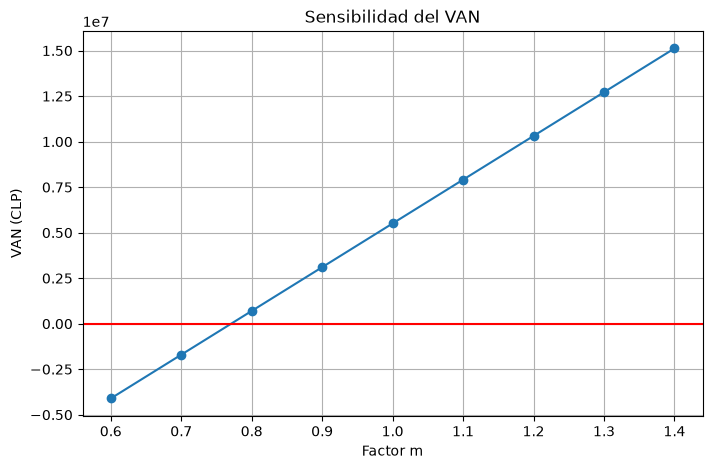

m critico(aproximado) = 0.75
VAN = -137441.26


In [59]:
import numpy as np
import numpy_financial as npf
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FlujoA= [-18522000,5000000,6500000,7500000,11000000]
r= (0.15*29 + 4)/100

mValores = [0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4]
VanSensibilidad = []


for m in mValores:

    Valores = [
        -18522000,
        5000000 * m,
        6500000 * m,
        7500000 * m,
        11000000 * m
    ]

    VAN = npf.npv(r, Valores)

    if abs(VAN) < 50000:
        print("m critico =", m)
        print("VAN =", VAN)
        break

for m in mValores:
    
    Valores = [-18522000 , 5000000 * m , 6500000 * m , 7500000 * m , 11000000 * m ]
    
    VAN = npf.npv(r, Valores)

    VanSensibilidad.append(VAN)

plt.figure(figsize=(8,5))

plt.plot(mValores,VanSensibilidad,marker="o")

plt.axhline(0,color="red")

plt.xlabel("Factor m")

plt.ylabel("VAN (CLP)")

plt.title("Sensibilidad del VAN")

plt.grid()

plt.show()


import numpy as np

for m in np.arange(0.60, 1.41, 0.01):

    Valores = [
        -18522000,
        5000000 * m,
        6500000 * m,
        7500000 * m,
        9000000 * m + 2000000
    ]

    VAN = npf.npv(r, Valores)

    if abs(VAN) < 140000:
        print("m critico(aproximado) =", round(m, 2))
        print("VAN =", round(VAN, 2))
        break

# Explicación Grafica y *m* Critico
*Ya con la tabla hecha podemos deducir que el valor critico debe ser un numero entre m = [0,7500~ -0,75812~] para que el* <b>VAN sea = 0</b> 

*Ahora que significa el grafico;*

*Utilizando nuestros conocimientos previos del van sabemos que sea el VAN negativo nosotros perdemos dinero y no se debe realizar el proyecto, sea positivo nosotros ganaremos dinero haciendo el proyecto por lo tanto ya con esto sabemos que para que almenos recuperemos todo el dinero obtenido al invertir en el proyecto debemos obtener un m = 0,75~ ya con esto en mente sabemos que*

#### <b>El proyecto A sera siempre rentable en el rango m = [0,76 - 1] </b>

#  Simulación de Monte Carlo

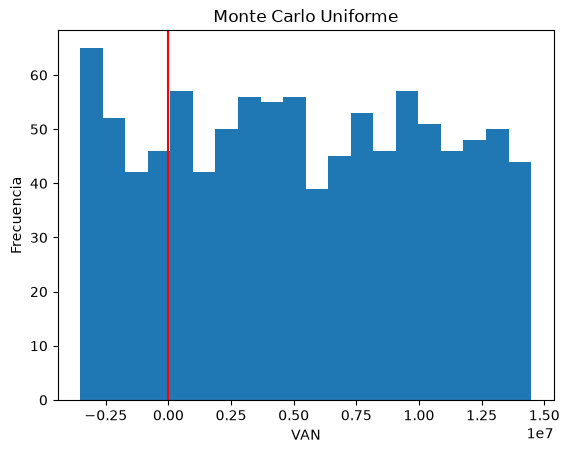

UNIFORME
Positivos: 799
Negativos: 201
% Positivos: 79.9
VAN Promedio: 5309309.216824581
Desv.Est: 5218043.302816162


In [60]:
rng = np.random.default_rng(2025730294)

m_uniforme = rng.uniform(0.60,1.40,1000)

VanUniforme = []

for m in m_uniforme:
    
    Valores = [
            -18522000,
            5000000 * m,
            6500000 * m,
            7500000 * m,
            9000000 * m + 2000000
        ]
            
    VAN = npf.npv(r, Valores)

    VanUniforme.append(VAN)
    
plt.hist(VanUniforme,bins=20)

plt.axvline(0,color='red')

plt.title("Monte Carlo Uniforme")

plt.xlabel("VAN")

plt.ylabel("Frecuencia")

plt.show()

PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)

print("UNIFORME")
print("Positivos:",PositivosU)
print("Negativos:",NegativosU)
print("% Positivos:",PositivosU/1000*100)
print("VAN Promedio:",np.mean(VanUniforme))
print("Desv.Est:",np.std(VanUniforme))

### En el grafico Uniforme podemos notar
*Que la mayoria de sus datos rondan con la misma frecuencia ente 43~53 aprox*

*Ademas algo interezante a notar es que si empezamos a ver la distribucion de barras aunque la mayoria se encuentran en rango de* <b> VAN POSITIVO </b> *, La varra mas alta(frecuente) se encuentra en el* <b> VAN </b> negativo lo que puede significar de que apesar de que genere un buen dinero* <b> NO ES UN PROYECTO NECESARIAMENTE ESTABLE </b> *esto en el sentido de que puede tener algun riesgo a considerar al crear tal proyecto*


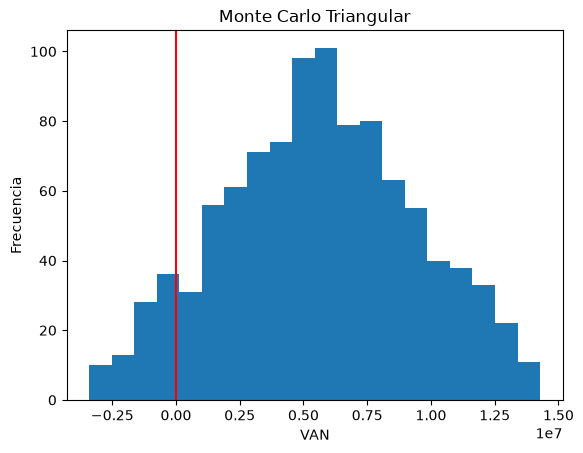

TRIANGULAR
Positivos: 919
Negativos: 81
% Positivos: 91.9
VAN Promedio: 5618014.971991348
Desv.Est: 3751388.9843767053


In [61]:
m_triangular = rng.triangular(0.60,1.00,1.40,1000)

VanTriangular = []

for m in m_triangular:

    Valores = [ -18522000,
                 5000000 * m,
                 6500000 * m,
                 7500000 * m,
                 9000000 * m + 2000000 ]
            
    VAN = npf.npv(r, Valores)

    VanTriangular.append(VAN)

plt.hist(VanTriangular,bins=20)

plt.axvline(0,color='red')

plt.title("Monte Carlo Triangular")

plt.xlabel("VAN")

plt.ylabel("Frecuencia")

plt.show()

PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)

PositivosT = np.sum(np.array(VanTriangular) > 0)
NegativosT = np.sum(np.array(VanTriangular) < 0)

print("TRIANGULAR")
print("Positivos:",PositivosT)
print("Negativos:",NegativosT)
print("% Positivos:",PositivosT/1000*100)
print("VAN Promedio:",np.mean(VanTriangular))
print("Desv.Est:",np.std(VanTriangular))

### En el grafico Triangular podemos notar
*Que la mayoria de sus datos no tienen un consistencia regular de frecuencia o tienen mucha frecuencia o tienen poca*

*En este grafico en particular podemos observar claramente como en este caso en particular hay una mayor posibilidad de ganancia, manteniedo la mayores probabilidades de obtener* <b> VAN POSITIVOS </b> *y particularmente una gran visión positiva del proyecto al demostrar que el proyecto va a salir adelante*

In [62]:
#Uniforme

rng = np.random.default_rng(2025730294)
m_uniforme = rng.uniform(0.60,1.40,1000)
VanUniforme = []
for m in m_uniforme:
    
    Valores = [
            -18522000,
            5000000 * m,
            6500000 * m,
            7500000 * m,
            9000000 * m + 2000000
        ]
            
    VAN = npf.npv(r, Valores)

    VanUniforme.append(VAN)
PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)


#triangular

m_triangular = rng.triangular(0.60,1.00,1.40,1000)
VanTriangular = []
for m in m_triangular:

    Valores = [ -18522000,
                 5000000 * m,
                 6500000 * m,
                 7500000 * m,
                 11000000 * m ]
            
    VAN = npf.npv(r, Valores)

    VanTriangular.append(VAN)

PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)

PositivosT = np.sum(np.array(VanTriangular) > 0)
NegativosT = np.sum(np.array(VanTriangular) < 0)

# tabla comparativa

TablaResultadosHistogramas = pd.DataFrame({
    "Histogramas":["Uniforme","Triangular"],
    "Positivos":[PositivosU,PositivosT],
    "Negativos:": [NegativosU,NegativosT],
    "% Positivos:":[PositivosU/1000*100,PositivosT/1000*100],
    "Van Promedio":[round(np.mean(VanUniforme),2), round(np.mean(VanTriangular),2)],
    "Desv.Est:":[round(np.std(VanUniforme),2) , round(np.std(VanTriangular),2)]
})

TablaResultadosHistogramas= TablaResultadosHistogramas.set_index("Histogramas")
display(TablaResultadosHistogramas)

,Positivos,Negativos:,% Positivos:,Van Promedio,Desv.Est:
Histogramas,,,,,
Uniforme,799,201,79.9,5309309.22,5218043.30
Triangular,906,94,90.6,5625148.61,3992503.57


# Comparaciones y observaciones de valores de ambos graficos

*Si comparamos a ambos graficos hay una gran diferencia entre las frecuencias en la que hay VAN positivo o negativo, donde en el uniforme al todas las simulaciones correrse una n veces equitativamente entre todos los valores de m se ve una tendencia de que el proyecto nos hara ganar o perder dinero*
*En cambio el Grafico triangular tiene una tendencia mas grande a que haya un VAN POSITIVO en promedio, donde es muy poco frecuente perder dinero donde se tiene la vista de que si o si al menos vamos a consegir el* <b> VAN ORIGINAL </b> *Osea m = 1.0 y por lo tanto tener una frecuencia*

*A pesar de todo lo dicho, igualmente si tomamos los datos numericos podemos ver que si comparamos los VAN en promedio de ambos graficos podemos ver que estan en un rango decente del van original.*

<b> VAN TRIANGULAR: 5625148.61 (clp) </b>

<b> VAN UNIFORME: 5309309.22 (clp) </b>

<b> VAN ORIGINAL: 5507026.07 (clp) </b>

*Lo que implica que es bastante seguro hacer el proyecto y que hay una posibilidad muy grande que el valor del proyecto se mantega en este rango entregado por lo VAN Promedio de los grafico, y me permite mantener mi opinion de que el proyecto si o si deberia de hacerse ya que demuestra una ganancia economica segura*

In [63]:
# ----------------------------------------------------------
# Ejercicio practico
# ----------------------------------------------------------

m = 0.85
k= 1

ValoresM = [ -18522000 , 5000000 * m, 6500000 * m, 7500000 * m, 9000000 * m + 2000000]
ValoresK = [ -18522000 , 5000000 * k, 6500000 * k, 7500000 * k, 9000000 * k + 2000000]

VAN_M = npf.npv(r, ValoresM)
VAN_K = npf.npv(r, ValoresK)

print("Van[m = 0.85]: ", round(VAN_M,2), " (v/s) ","Van[m = 1.0]: ", round(VAN_K,2))


Van[m = 0.85]:  2120345.67  (v/s)  Van[m = 1.0]:  5507026.07


Finalmente, realice una demostración práctica calculando el VAN del proyecto seleccionado con un factor
de ajuste m = 0,85. Compare el resultado con el escenario base (m = 1,00) y explique su efecto económico.
La demostración deberá mostrar la ejecución del código y los resultados obtenidos, sin alterar el
desarrollo original de la tarea.

---

# CODIGO ORIGINAL(python) UTILIZADO PARA SACAR EL VALOR NETO DE TODA LA TAREA

In [ ]:
# ----------------------------------------------------------
# IMPORTACIÓN DE LIBRERÍAS
# ----------------------------------------------------------


import numpy as np
import numpy_financial as npf
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

#Tarea3_2025730294_García
#sea mi rol 202573029-4 ultimos 2 digitos componen la variable k = 94

def Factor_invercion(K):
    F = 1 + K/1000
    return(F)

#tasa de descuento real efectiva anual 
def TdescuentoRFA(K):
    R = 0.15 * K
    R= R+4
    R= R/100
    return(R)

def Sacar_FlujoCaja(**Base):
    FC = 0
    for Capital in Base:
        FC= Base[Capital]/((1+r)**i)
        print(FC)
        print(" || ")
    print("\n")
    return(FC)
    

# ==========================================================
# INICIO DEL PROGRAMA
# ==========================================================

k= 29
semilla= 2025730294
f= Factor_invercion(k)
r= TdescuentoRFA(k)

print(k, "(K) ", f, "(Factor de inversión) ", round(r,2), "(Tasa de descuento) ", semilla, "(rol)\n")
#calculos de flujo de caja
# ==========================================================
# PROYECTO A
# ==========================================================

FlujoDeCaja_A = {
    # La inversión inicial se ajusta por f
    'inversion_inicial (Año 0)': -18000000 * f,
        'Año 1':  5000000,
        'Año 2': 6500000,
        'Año 3': 7500000,
        'Año 4': 9000000,
        'Recuperacion(Año 4)': 2000000
}

FC = 0
i= 0
# Lista final de flujos usada para VAN y TIR
FlujoA= [0,0,0,0,0]

# Construcción del flujo de caja
for Capital in FlujoDeCaja_A:
    
    FC= FlujoDeCaja_A[Capital] #/((1+r)**i)
    if i == 5:
        FlujoA[4]+= FC
        i= i -1
        print(FlujoA[i], " ||")
    
    # Cuando llega la recuperación del año 4
    # se suma al flujo del mismo año
    else:
        FlujoA[i]= FC
        print(FlujoA[i], " ||")
        i+= 1
    
    
    
# Cálculo del VAN y la TIR
VanA= round(npf.npv(r,FlujoA),2)
TirA= round(npf.irr(FlujoA),2)
print("Van FC_ A: ",VanA, "Tir FC_ A: ", TirA*100 , "%")
print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

FlujoDeCaja_B = {
    'inversion_inicial (Año 0)': -36000000 * f,
            'Año 1':  7000000,
            'Año 2': 10000000,
            'Año 3': 14000000,
            'Año 4': 18000000,
            'Recuperacion(Año 4)': 4000000
}

FC= 0
i= 0
FlujoB= [0,0,0,0,0]
for Capital in FlujoDeCaja_B:
    
    FC= FlujoDeCaja_B[Capital] #/((1+r)**i)
    if i == 5:
        FlujoB[4]+= FC
        i= i -1
        print(FlujoB[i], " ||")
    else:
        FlujoB[i]= FC
        print(FlujoB[i], " ||")
        i+= 1
    
    
   
VanB= round(npf.npv(r,FlujoB),2)
TirB= round(npf.irr(FlujoB),2)
print("Van FC_ B: ",VanB, "Tir FC_ B: ", TirB*100, "%")
print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

FlujoDeCaja_C = {
    'inversion_inicial (Año 0)': -10000000 * f,
        'Año 1':  4500000,
        'Año 2': 3000000,
        'Año 3': 5500000,
        'Año 4': 3000000,
        'Recuperacion(Año 4)': 1000000
}

FC= 0
i= 0
FlujoC= [0,0,0,0,0]
for Capital in FlujoDeCaja_C:
    
    FC= FlujoDeCaja_C[Capital] #/((1+r)**i)
    if i == 5:
            FlujoC[4]+= FC
            i= i -1
            print(FlujoC[i], " ||")
    else:
        FlujoC[i]= FC
        print(FlujoC[i], " ||")
        i+= 1
    
    

VanC= round(npf.npv(r,FlujoC),2)
TirC= round(npf.irr(FlujoC),2)
print("Van FC_ B: ",VanC, "Tir FC_ B: ", TirC*100,"%")
print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")

# ==========================================================
# TABLAS RESUMEN
# ==========================================================

# Tabla de flujos construidos
print("Resumen: (↓)\n")

TablaFlujos = pd.DataFrame({
    "Proyecto": ["A", "B", "C"],
    "Año 0": [FlujoA[0], FlujoB[0], FlujoC[0]],
    "Año 1": [FlujoA[1], FlujoB[1], FlujoC[1]],
    "Año 2": [FlujoA[2], FlujoB[2], FlujoC[2]],
    "Año 3": [FlujoA[3], FlujoB[3], FlujoC[3]],
    "Año 4": [FlujoA[4], FlujoB[4], FlujoC[4]]
})

TablaFlujos = TablaFlujos.set_index("Proyecto")

display(TablaFlujos)

# Tabla de indicadores financieros
TablaResultados = pd.DataFrame({
    "Proyecto":["A","B","C"],
    "VAN(CLP)":[VanA,VanB,VanC],
    "TIR (%)":[TirA*100,TirB*100,TirC*100],
    "Inversión Inicial":[FlujoA[0],FlujoB[0],FlujoC[0]]
})

TablaResultados= TablaResultados.set_index("Proyecto")

display(TablaResultados)

"""
Parte 2; en jupiter explicación de porque se escoje el proyecto A
"""


# ==========================================================
# PARTE 3 - ANÁLISIS DE SENSIBILIDAD
# ==========================================================

#sea el proyecto escojido el A
# Se analiza el proyecto seleccionado
mValores = [0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4]
# Lista donde se almacenarán los VAN calculados

VanSensibilidad = []

i=0

# Copia auxiliar del flujo original
Valor = [0,0,0,0,0]

while (i < 5):
    Valor[i] = FlujoA[i]
    i+= 1

Valores = [0,0,0,0,0]

# Evaluación de los nueve escenarios
for m in mValores:
    
    # La inversión inicial queda fija
    Valores[0] = Valor[0]
    
    # Los flujos operativos se multiplican por m
    Valores[1] = Valor[1] * m
    Valores[2] = Valor[2] * m
    Valores[3] = Valor[3] * m
    Valores[4] = (Valor[4]-2000000) * m + 2000000 
    
    VAN = npf.npv(r, Valores)

    #agregamos VAN en cada ciclo
    VanSensibilidad.append(VAN)

    print("m =",m)
    print("VAN =",VAN)
    print("----------------")
    
    
# Tabla de sensibilidad
TablaSensibilidadesM = pd.DataFrame({
    "Valor de [ m ]": [0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4],
    "Van": [round(VanSensibilidad[0],2),round(VanSensibilidad[1],2),round(VanSensibilidad[2],2)
            ,round(VanSensibilidad[3],2),round(VanSensibilidad[4],2), round(VanSensibilidad[5],2)
            ,round(VanSensibilidad[6],2),round(VanSensibilidad[7],2),round(VanSensibilidad[8],2),
            ]
})

TablaSensibilidadesM = TablaSensibilidadesM.set_index("Valor de [ m ]")
display(TablaSensibilidadesM)

print("~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~")
print("Resumen:")

# Gráfico VAN vs m
plt.figure(figsize=(8,5))

plt.plot(mValores,VanSensibilidad,marker="o")

plt.axhline(0,color="red")

plt.xlabel("Factor m")

plt.ylabel("VAN (CLP)")

plt.title("Sensibilidad del VAN")

plt.grid()

plt.show()

"""
explicacion grafico en jupyter
"""

# ==========================================================
# BÚSQUEDA DEL VALOR CRÍTICO DE m
# ==========================================================
# Se busca el valor de m donde VAN≈0
for m in np.arange(0.6,1.41,0.01):
    
    Valores[0] = Valor[0]
    Valores[1] = Valor[1] * m
    Valores[2] = Valor[2] * m
    Valores[3] = Valor[3] * m
    Valores[4] = (Valor[4]-2000000) * m + 2000000     
        
    VAN = npf.npv(r, Valores)
    
    VanSensibilidad.append(VAN)

    
    # Se considera suficientemente cercano a cero
    if abs(VAN) < 50000:
        print("m critico =",m)
        print("VAN =",VAN)
        break


# ----------------------------------------------------------
# CREACIÓN DE LA TABLA DE SENSIBILIDAD
# ----------------------------------------------------------
# Se construye un DataFrame para mostrar
# los resultados del análisis de sensibilidad.
# Cada fila representa un valor distinto del factor m y
# su respectivo VAN calculado anteriormente.

TablaSensibilidadesM = pd.DataFrame({

    # Valores evaluados para el factor de ajuste m
    "Valor de [ m ]": [0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4],

    # VAN obtenido para cada valor de m.
    # Se utiliza round(...,2) para mostrar los resultados
    # con dos decimales y facilitar la lectura.
    "Van": [
        round(VanSensibilidad[0],2),
        round(VanSensibilidad[1],2),
        round(VanSensibilidad[2],2),
        round(VanSensibilidad[3],2),
        round(VanSensibilidad[4],2),
        round(VanSensibilidad[5],2),
        round(VanSensibilidad[6],2),
        round(VanSensibilidad[7],2),
        round(VanSensibilidad[8],2),
    ]
})

TablaSensibilidadesM = TablaSensibilidadesM.set_index("Valor de [ m ]")

# Muestra la tabla en formato tabular dentro del Notebook.
display(TablaSensibilidadesM)
print("~~~~~~~~~~~~~~~~~~~~~+")

# ==========================================================
# PARTE 4 - SIMULACIÓN DE MONTE CARLO
# ==========================================================


# Generador aleatorio reproducible
rng = np.random.default_rng(2025730294)

# Distribución uniforme
m_uniforme = rng.uniform(0.60,1.40,1000)

VanUniforme = []

# Cálculo de 1000 VAN
for m in m_uniforme:
    
    Valores[0] = Valor[0]
    Valores[1] = Valor[1] * m
    Valores[2] = Valor[2] * m
    Valores[3] = Valor[3] * m
    Valores[4] = (Valor[4]-2000000) * m + 2000000     
            
    VAN = npf.npv(r, Valores)

    VanUniforme.append(VAN)


# Distribución triangular
m_triangular = rng.triangular(0.60,1.00,1.40,1000)

VanTriangular = []

for m in m_triangular:

    Valores[0] = Valor[0]
    Valores[1] = Valor[1] * m
    Valores[2] = Valor[2] * m
    Valores[3] = Valor[3] * m
    Valores[4] = (Valor[4]-2000000) * m + 2000000    
            
    VAN = npf.npv(r, Valores)

    VanTriangular.append(VAN)

# ----------------------------------------------------------
# HISTOGRAMA DISTRIBUCIÓN UNIFORME
# ----------------------------------------------------------


plt.hist(VanUniforme,bins=20)

plt.axvline(0,color='red')

plt.title("Monte Carlo Uniforme")

plt.xlabel("VAN")

plt.ylabel("Frecuencia")

plt.show()

# ----------------------------------------------------------
# HISTOGRAMA DISTRIBUCIÓN TRIANGULAR
# ----------------------------------------------------------

plt.hist(VanTriangular,bins=20)

plt.axvline(0,color='red')

plt.title("Monte Carlo Triangular")

plt.xlabel("VAN")

plt.ylabel("Frecuencia")

plt.show()

# ----------------------------------------------------------
# ESTADÍSTICAS RESUMEN
# ----------------------------------------------------------

PositivosU = np.sum(np.array(VanUniforme) > 0)
NegativosU = np.sum(np.array(VanUniforme) < 0)

PositivosT = np.sum(np.array(VanTriangular) > 0)
NegativosT = np.sum(np.array(VanTriangular) < 0)

print("UNIFORME")
print("Positivos:",PositivosU)
print("Negativos:",NegativosU)
print("% Positivos:",PositivosU/1000*100)
print("VAN Promedio:",np.mean(VanUniforme))
print("Desv.Est:",np.std(VanUniforme))

print()

print("TRIANGULAR")
print("Positivos:",PositivosT)
print("Negativos:",NegativosT)
print("% Positivos:",PositivosT/1000*100)
print("VAN Promedio:",np.mean(VanTriangular))
print("Desv.Est:",np.std(VanTriangular))

# ----------------------------------------------------------
# TABLA COMPARATIVA FINAL
# ----------------------------------------------------------


TablaResultadosHistogramas = pd.DataFrame({
    "Histogramas":["Uniforme","Triangular"],
    "Positivos":[PositivosU,PositivosT],
    "Negativos:": [NegativosU,NegativosT],
    "% Positivos:":[PositivosU/1000*100,PositivosT/1000*100],
    "Van Promedio":[round(np.mean(VanUniforme),2), round(np.mean(VanTriangular),2)],
    "Desv.Est:":[round(np.std(VanUniforme),2) , round(np.std(VanTriangular),2)]
})

TablaResultadosHistogramas= TablaResultadosHistogramas.set_index("Histogramas")
display(TablaResultadosHistogramas)
